## Running with the standalone HICASM library

Run this notebook from the directory containing `hicasm.py`. Install dependencies with
`%pip install -r requirements.txt` in the notebook's Python environment, then restart
its kernel and run all cells in order. Model initialization includes adaptation;
the complete benchmark, especially Test 5, takes longer than the small demo.
Results are written to `results/HIESM_v1_2_canonical/`.

The historical HIESM V1.2 labels below are retained for the benchmark. All model
computation now uses `hicasm.HICASM`; the legacy `reservoir`, `reservoir_references`,
`scalability_evaluation`, `scaffold`, and `readout` modules are no longer required.
Test 5 applies feature masks to the model's input projection before calling
`address_from_C`. The diagnostic wrapper uses the library's internal `_readout`
method because this benchmark needs to inspect and replay intermediate states.

# HIESM V1.2 — Frozen Canonical Model

**HIESM V1.2 is the frozen hard-WTA model.** It retains the V1.1 $R\to C\to A\to B\to S\to R$ architecture, parameters, adaptation, storage rules, and downstream replay. Its defining version change is episode-level deterministic hard winner-take-all (WTA) in A, replacing V1.1's relative soft competition. The previous V1/V1.1 notebooks are archived and are no longer active model definitions.

At retrieval, $D_k=\sum_t h_{k,t}$ is computed as in V1.1, then hard WTA retains only $D_{k^*}$ for $k^*=\arg\max_kD_k$. The surviving activity is passed through the stored A$\to$B association, $u_B=D^{\mathrm{WTA}}V$, and normalized before entering $S$. There is no direct barcode lookup, $w_k$ vector, barcode averaging, added noise, softmax, TopK, or active $\lambda_A$. Exact ties follow deterministic `numpy.argmax` first-index behavior.

| Test | Historical source | Exact settings recovered? | Notes |
|---|---|---|---|
| 1 overlap / mismatch position | `sequence_memory_v1_teacher_episodic_task_benchmark.ipynb`, cells 6–8 | Yes | $L=8$, overlap grid 0–0.9, $M=50$; positional control $M=100$, 50 pairs, all 8 mismatch positions. |
| 2 partial location / length | historical V1 teacher notebook cell 10 and factorized-A teacher notebook Test 2 | Yes | Reversed-order banks; prefix/middle/suffix; $m=2,3,4$; $M=5,10,25,50,100$. |
| 3 unique middle | factorized-A teacher notebook Test 3 | Yes | $L=8$, marker at zero-based position 3; $M=5,10,25$; fillers exclude all markers. |
| 4 ambiguity / added evidence | factorized-A teacher notebook Test 4 | Yes | $M=10,50,100$; 3 seeds × 4 banks × 5 pairs; shared positions 3–5 and discriminator at position 6 (one-based). |
| 5 feature masking | factorized-A teacher notebook Test 5 | Yes | $L=8$, $M=10,50,100$, middle four-event cue, $q=0:.1:1$, 4 nested-mask replicates. |

The canonical realization is fixed by `MODEL_SEED=321001` and `ADAPT_SEED=721001`. The three `BANK_SEEDS` generate episode banks only; they are not model realizations. The separate archived V1.2 model-seed robustness notebook evaluates three independently initialized models.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import Markdown,display
from hicasm import Config, HICASM, sample_unique_sequences
plt.style.use("seaborn-v0_8-whitegrid");pd.set_option("display.max_columns",100)
NR,NC,NB,NS,H=32,160,640,1024,6;G=1.05;TH=2.84;POWER=2.;BETA=.375;EF=1e-4
MODEL_SEED,ADAPT_SEED=321001,721001;BANK_SEEDS=[321001,321002,321003];SEEDS=BANK_SEEDS;BANKS=4;L=8
LOADS=[5,10,25,50,100];CUE_LENGTHS=[2,3,4];CUE_TYPES=["prefix","middle","suffix"]
OVERLAPS=[0,.25,.5,.75,.9];TEST4_M=[10,50,100];QGRID=np.round(np.linspace(0,1,11),1);MASK_REPS=4
ROOT=Path("results/HIESM_v1_2_canonical");FIG=ROOT/"figures";FIG.mkdir(parents=True,exist_ok=True);EPS=1e-12
assert TH==2.84 and POWER==2 and H==6
# Initialize the complete frozen model once; adaptation is handled by HICASM.
model = HICASM(Config(N_R=NR, N_C=NC, N_B=NB, N_S=NS, H=H,
                      g=G, theta_A=TH, p_A=POWER, beta=BETA,
                      epsilon_factor=EF, model_seed=MODEL_SEED,
                      adaptation_seed=ADAPT_SEED))
r = model  # Test 5 uses the model's W_CC and W_CR for feature masking.
muC, muB = model.mu_C, model.mu_B
SETTINGS=pd.DataFrame([
 ["Test 1","V1.0 teacher cells 6–8",True,"overlap grid; positional 7/8"],["Test 2","V1 teacher cell 10 + factorized Test 2",True,"locations and m grid"],
 ["Test 3","factorized Test 3",True,"unique marker generator"],["Test 4","factorized Test 4",True,"3×4×5 pair protocol"],["Test 5","factorized Test 5",True,"nested W_CR masking"]],columns=["Test","Historical source","Exact settings recovered","Notes"]);SETTINGS.to_csv(ROOT/"historical_settings_recovered.csv",index=False);display(SETTINGS)

,Test,Historical source,Exact settings recovered,Notes
0,Test 1,V1.0 teacher cells 6–8,True,overlap grid; positional 7/8
1,Test 2,V1 teacher cell 10 + factorized Test 2,True,locations and m grid
2,Test 3,factorized Test 3,True,unique marker generator
3,Test 4,factorized Test 4,True,3×4×5 pair protocol
4,Test 5,factorized Test 5,True,nested W_CR masking


In [2]:
def traj(ep):
 return model.C_trajectory(ep)
def benc(C):
 return model.encode_B(C)
def mem(ep):
 memory = model.build_memory(ep)
 # Keep the experiment-facing keys while delegating model computation to hicasm.py.
 return {'memory':memory,'ep':memory.episodes,'T':memory.C_trajectory,
         'Dctx':memory.context_values,'B':memory.barcodes,
         'V':memory.barcode_values,'S':memory.S_states,'M':memory.M,'L':memory.L}
def fromq(mm,q):
 addressed = model.address_from_C(mm['memory'],q)
 D, D_wta, Br = addressed['D'], addressed['D_wta'], addressed['barcode']
 u = D_wta @ mm['V']  # Diagnostic used by the historical barcode-margin test.
 Sr = model.replay_S(Br,mm['L'])
 pred = model._readout(mm['memory'],Sr)
 return D,D_wta,u,Br,Sr,pred
def events(mm,cue):
 return fromq(mm,model.run_C(np.asarray(cue,int)))
def cosrows(X,Y):return np.sum(X*Y,1)/np.maximum(np.linalg.norm(X,axis=1)*np.linalg.norm(Y,axis=1),EPS)
def rows(mm,D,D_wta,u,Br,Sr,pred,target,extra=None):
 out=[];target=np.asarray(target);extra=extra or {}
 for i,t in enumerate(target):
  wrong=np.delete(D[i],t);winner=int(D[i].argmax());truth=mm['ep'][t]
  rec={'target':t,'winner':winner,'D_target':D[i,t],'D_wrong_max':wrong.max(),'D_max':D[i,winner],'D_margin':D[i,t]-wrong.max(),'winner_is_target':winner==t,'A_top1':winner==t,
  'barcode_similarity':cosrows((Br[i]-muB)[None,:],(mm['B'][t]-muB)[None,:])[0],'S0_similarity':cosrows(Sr[i,0][None,:],mm['S'][t,0][None,:])[0],
  'event_accuracy':np.mean(pred[i]==truth),'exact_replay':np.array_equal(pred[i],truth),'D_vector':json.dumps(D[i].tolist()),'D_wta_vector':json.dumps(D_wta[i].tolist()),'u_B_norm':np.linalg.norm(u[i]),**extra};out.append(rec)
 return out
def orderbank(rng,M,L=8):
 ep=[]
 while len(ep)+1<M:
  x=rng.choice(NR,L,replace=False);ep.extend([x,x[::-1]])
 while len(ep)<M:ep.append(rng.choice(NR,L,replace=False))
 return np.asarray(ep)
def cueslice(kind,m):return 0 if kind=='prefix' else (L-m)//2 if kind=='middle' else L-m
def save(fig,name):fig.savefig(FIG/name,dpi=180,bbox_inches='tight');plt.show()

## 1. Historical Test 1 — overlap and differing-event position

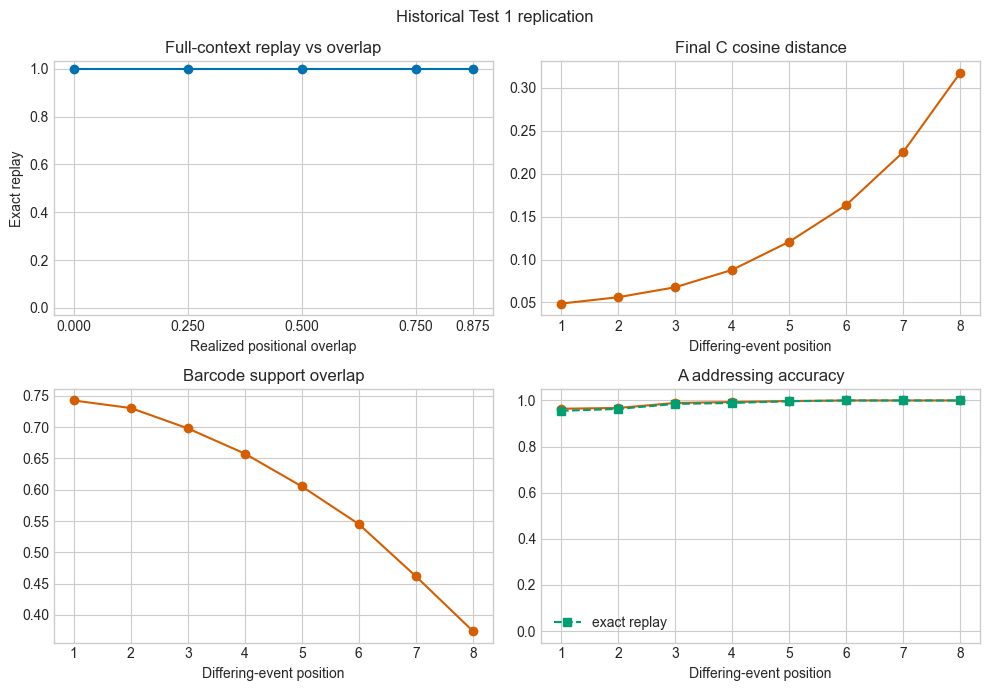

,target,winner,D_target,D_wrong_max,D_max,D_margin,winner_is_target,A_top1,barcode_similarity,S0_similarity,event_accuracy,exact_replay,u_B_norm,seed,bank,requested_overlap
realized_overlap,,,,,,,,,,,,,,,,
0.000,24.5,24.5,596.617597,122.114927,596.617597,474.502670,1.0,1.0,1.0,1.0,1.0,1.0,3374.373326,321002.0,1.5,0.00
0.250,24.5,24.5,596.579016,124.545607,596.579016,472.033409,1.0,1.0,1.0,1.0,1.0,1.0,3373.303064,321002.0,1.5,0.25
0.500,24.5,24.5,597.880092,115.569728,597.880092,482.310364,1.0,1.0,1.0,1.0,1.0,1.0,3388.689696,321002.0,1.5,0.50
0.750,24.5,24.5,593.644474,127.238853,593.644474,466.405621,1.0,1.0,1.0,1.0,1.0,1.0,3330.023106,321002.0,1.5,0.75
0.875,24.5,24.5,575.353824,238.052244,575.353824,337.301579,1.0,1.0,1.0,1.0,1.0,1.0,3225.878485,321002.0,1.5,0.90


,target,winner,D_target,D_wrong_max,D_max,D_margin,winner_is_target,A_top1,barcode_similarity,S0_similarity,event_accuracy,exact_replay,u_B_norm,seed,bank,C_cosine_distance,B_support_overlap,barcode_collision
different_position,,,,,,,,,,,,,,,,,,
1,49.5,49.492500,594.383683,531.313098,594.865087,63.070585,0.964167,0.964167,0.991442,0.991161,0.994375,0.955000,3338.711248,321002.0,1.5,0.048618,0.742498,0.0
2,49.5,49.502500,596.279608,523.358295,596.713625,72.921313,0.967500,0.967500,0.991823,0.991535,0.995417,0.963333,3345.511630,321002.0,1.5,0.056010,0.730426,0.0
3,49.5,49.499167,603.633354,515.267219,603.746241,88.366134,0.989167,0.989167,0.996807,0.996601,0.998125,0.985000,3413.129118,321002.0,1.5,0.067624,0.697957,0.0
4,49.5,49.500000,599.149893,486.881150,599.285570,112.268743,0.993333,0.993333,0.997828,0.997760,0.998646,0.989167,3384.661418,321002.0,1.5,0.087832,0.657675,0.0
5,49.5,49.500833,597.997794,447.426947,598.024620,150.570847,0.997500,0.997500,0.999226,0.999179,0.999583,0.996667,3372.799852,321002.0,1.5,0.120562,0.605281,0.0
6,49.5,49.500000,588.668791,392.472626,588.668791,196.196165,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3300.844901,321002.0,1.5,0.163296,0.545090,0.0
7,49.5,49.500000,589.980281,329.446083,589.980281,260.534198,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3309.079175,321002.0,1.5,0.224981,0.461797,0.0
8,49.5,49.500000,592.462853,248.047487,592.462853,344.415366,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3352.773663,321002.0,1.5,0.317324,0.374258,0.0


In [3]:
ov=[];pos=[]
for seed in SEEDS:
 for bank in range(BANKS):
  for overlap in OVERLAPS:
   rng=np.random.default_rng(seed+500000+10000*bank+int(overlap*100));shared=int(round(overlap*L));ep=[];real=[]
   while len(ep)<50:
    a=rng.choice(NR,L,replace=False);b=np.empty(L,int);b[:shared]=a[:shared];avail=np.setdiff1d(np.arange(NR),a);b[shared:]=rng.choice(avail,L-shared,replace=False);ep.extend([a,b]);real.append(np.mean(a==b))
   ep=np.asarray(ep[:50]);mm=mem(ep);D,E,u,Br,Sr,pred=events(mm,ep)
   for rec in rows(mm,D,E,u,Br,Sr,pred,np.arange(50),{'seed':seed,'bank':bank,'requested_overlap':overlap,'realized_overlap':np.mean(real)}):ov.append(rec)
  for dp in range(8):
   rng=np.random.default_rng(seed+600000+10000*bank+dp);ep=[];pairs=[]
   while len(ep)<100:
    a=rng.choice(NR,8,replace=False);b=a.copy();b[dp]=rng.choice(np.setdiff1d(np.arange(NR),a));pairs.append((len(ep),len(ep)+1));ep.extend([a,b])
   ep=np.asarray(ep);mm=mem(ep);D,E,u,Br,Sr,pred=events(mm,ep);base=rows(mm,D,E,u,Br,Sr,pred,np.arange(100))
   for a,b in pairs:
    Cdist=1-cosrows(mm['T'][a,-1][None,:],mm['T'][b,-1][None,:])[0];Ba=mm['B'][a];Bb=mm['B'][b];Bover=np.sum(Ba*Bb)/max(np.sum(Ba),EPS)
    for j in [a,b]:pos.append({**base[j],'seed':seed,'bank':bank,'different_position':dp+1,'C_cosine_distance':Cdist,'B_support_overlap':Bover,'barcode_collision':np.array_equal(Ba,Bb)})
OV=pd.DataFrame(ov);POS=pd.DataFrame(pos);OV.to_csv(ROOT/'test1_overlap.csv',index=False);POS.to_csv(ROOT/'test1_differing_position.csv',index=False)
fig,ax=plt.subplots(2,2,figsize=(10,7));o=OV.groupby('realized_overlap').mean(numeric_only=True);ax[0,0].plot(o.index,o.exact_replay,'o-',color='#0072B2');ax[0,0].set(title='Full-context replay vs overlap',xlabel='Realized positional overlap',ylabel='Exact replay',ylim=(-.03,1.03),xticks=o.index)
ps=POS.groupby('different_position').mean(numeric_only=True);metrics=[('C_cosine_distance','Final C cosine distance'),('B_support_overlap','Barcode support overlap'),('A_top1','A addressing accuracy')]
for a,(m,t) in zip([ax[0,1],ax[1,0],ax[1,1]],metrics):a.plot(ps.index,ps[m],'o-',color='#D55E00');a.set(title=t,xlabel='Differing-event position');
ax[1,1].plot(ps.index,ps.exact_replay,'s--',color='#009E73',label='exact replay');ax[1,1].set_ylim(-0.05,1.05);ax[1,1].legend();fig.suptitle('Historical Test 1 replication');fig.tight_layout();save(fig,'figure1_test1_overlap_position.png');display(o);display(ps)

### Test 1 suffix-overlap control

The original overlap grid shares a prefix. This matched control instead shares the final $k$ positions: the two episodes have identical suffixes and deliberately non-overlapping relations before that suffix. It therefore asks whether increasing positional overlap near the recency-favored end of $C$ preserves exact downstream replay. All other Test 1 settings remain unchanged.

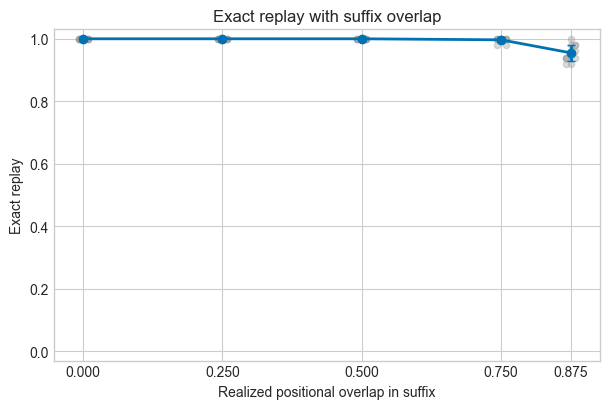

,realized_overlap,mean,std
0,0.000,1.000000,0.000000
1,0.250,1.000000,0.000000
2,0.500,1.000000,0.000000
3,0.750,0.996667,0.007785
4,0.875,0.955000,0.025761


In [4]:
suffix_ov=[]
for seed in SEEDS:
 for bank in range(BANKS):
  for overlap in OVERLAPS:
   rng=np.random.default_rng(seed+550000+10000*bank+int(overlap*100));shared=int(round(overlap*L));ep=[];real=[]
   while len(ep)<50:
    a=rng.choice(NR,L,replace=False);b=rng.choice(np.setdiff1d(np.arange(NR),a),L,replace=False)
    if shared>0:b[-shared:]=a[-shared:]
    ep.extend([a,b]);real.append(np.mean(a==b))
   ep=np.asarray(ep[:50]);mm=mem(ep);D,E,u,Br,Sr,pred=events(mm,ep)
   extra={'seed':seed,'bank':bank,'requested_overlap':overlap,'realized_overlap':np.mean(real),'overlap_location':'suffix'}
   suffix_ov.extend(rows(mm,D,E,u,Br,Sr,pred,np.arange(50),extra))
SUFFIX_OV=pd.DataFrame(suffix_ov);SUFFIX_OV.to_csv(ROOT/'test1_suffix_overlap.csv',index=False)
suffix_bank=SUFFIX_OV.groupby(['realized_overlap','seed','bank'],as_index=False).exact_replay.mean()
suffix_summary=suffix_bank.groupby('realized_overlap').exact_replay.agg(['mean','std']).reset_index()
fig,ax=plt.subplots(figsize=(6.2,4.2))
for (_,seed_rows),dx in zip(suffix_bank.groupby('seed'),[-.008,0,.008]):
 ax.scatter(seed_rows.realized_overlap+dx,seed_rows.exact_replay,s=20,alpha=.35,color='#999999',zorder=1)
ax.errorbar(suffix_summary.realized_overlap,suffix_summary['mean'],yerr=suffix_summary['std'],fmt='o-',lw=2,capsize=3,color='#0072B2',zorder=2)
ax.set(title='Exact replay with suffix overlap',xlabel='Realized positional overlap in suffix',ylabel='Exact replay',ylim=(-.03,1.03),xticks=suffix_summary.realized_overlap)
fig.tight_layout();save(fig,'figure1b_test1_suffix_overlap.png');display(suffix_summary)

## 2. Historical Test 2 — partial cue location and length

The bank contains same-item/reversed-order pairs. Cue starts are exactly prefix 0, middle $(8-m)//2$, and suffix $8-m$. No obsolete alpha is introduced; C remains frozen at $g=1.05$.

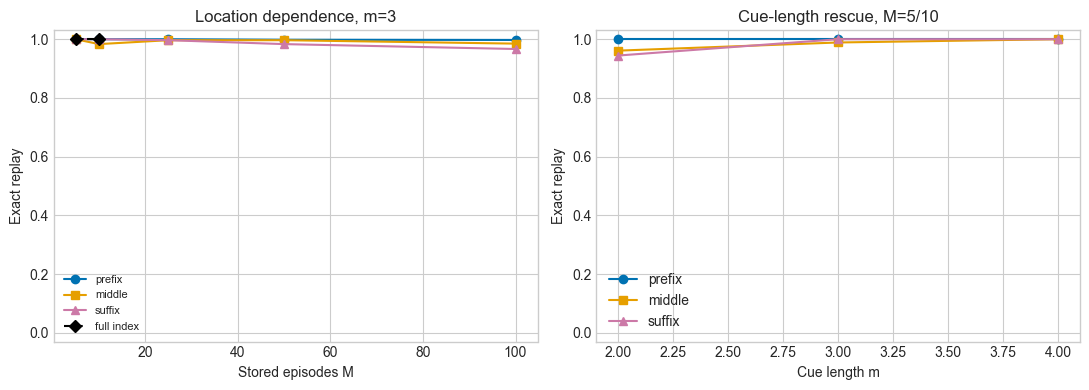

target     winner    D_target  D_wrong_max  \
M   cue_type cue_length                                               
5   middle   2              2.0   1.966667  176.175929    60.066920   
             3              2.0   2.000000  320.197238    59.357363   
             4              2.0   2.000000  422.822553    63.492461   
    prefix   2              2.0   2.000000  236.674812    55.987414   
             3              2.0   2.000000  386.461397    66.210867   
             4              2.0   2.000000  492.917273    55.068275   
    suffix   2              2.0   2.033333  164.610961    85.133867   
             3              2.0   2.000000  284.592401    81.647244   
             4              2.0   2.000000  385.807092    77.780798   
10  middle   2              4.5   4.491667  177.357695    79.668280   
             3              4.5   4.516667  319.222749    85.945405   
             4              4.5   4.500000  412.129029    90.545483   
    prefix   2              4.5   4.500000  240.202367    73.610081   
             3              4.5   4.500000  393.844997    88.990129   
             4              4.5   4.500000  502.853281    87.687280   
    suffix   2              4.5   4.591667  170.011341    96.262315   
             3              4.5   4.500000  292.784957    94.529399   
             4              4.5   4.500000  398.115682    96.671193   
25  middle   2             12.0  12.366667  177.709045    97.346223   
             3             12.0  12.013333  324.455038   106.644599   
             4             12.0  12.000000  408.604054    99.607918   
    prefix   2             12.0  11.903333  230.925606    85.968974   
             3             12.0  12.000000  393.802044    95.855510   
             4             12.0  12.000000  499.085296   100.231971   
    suffix   2             12.0  11.883333  164.207136    99.174608   
             3             12.0  12.013333  286.990595   106.449266   
             4             12.0  12.000000  385.990973   103.372592   
50  middle   2             24.5  24.896667  181.434937   121.889747   
             3             24.5  24.423333  324.043347   134.061409   
             4             24.5  24.441667  414.623625   127.931901   
    prefix   2             24.5  24.255000  239.291119   117.222961   
             3             24.5  24.460000  391.405733   126.161288   
             4             24.5  24.500000  495.145787   130.811619   
    suffix   2             24.5  24.763333  166.062907   121.014762   
             3             24.5  24.561667  291.499776   129.781772   
             4             24.5  24.500000  392.490769   130.226541   
100 middle   2             49.5  49.387500  176.526696   142.242084   
             3             49.5  49.478333  316.728115   153.339553   
             4             49.5  49.490000  418.748473   155.584914   
    prefix   2             49.5  48.028333  237.434008   146.210390   
             3             49.5  49.469167  392.117927   156.586727   
             4             49.5  49.500000  493.930886   152.832049   
    suffix   2             49.5  49.281667  167.137333   146.934038   
             3             49.5  49.429167  293.787421   156.621171   
             4             49.5  49.520000  394.092618   153.963279   

                              D_max    D_margin  winner_is_target    A_top1  \
M   cue_type cue_length                                                       
5   middle   2           177.145336  116.109010          0.983333  0.983333   
             3           320.197238  260.839875          1.000000  1.000000   
             4           422.822553  359.330092          1.000000  1.000000   
    prefix   2           236.674812  180.687397          1.000000  1.000000   
             3           386.461397  320.250530          1.000000  1.000000   
             4           492.917273  437.848998          1.000000  1.000000   
    suffix   2           165.219634   79.477094        

M   cue_type  
5   full index    1.0
10  full index    1.0
Name: accuracy, dtype: float64

In [5]:
t2=[];cache={};t2_reference=[]
for seed in SEEDS:
 for bank in range(BANKS):
  for M in LOADS:
   ep=orderbank(np.random.default_rng(seed+100000*bank+1000*L+M),M,L);mm=mem(ep);cache[(seed,bank,M)]=mm
   for kind in CUE_TYPES:
    for m in CUE_LENGTHS:
     st=cueslice(kind,m);D,E,u,Br,Sr,pred=events(mm,ep[:,st:st+m]);t2.extend(rows(mm,D,E,u,Br,Sr,pred,np.arange(M),{'seed':seed,'bank':bank,'M':M,'cue_type':kind,'cue_length':m}))
   if M in [5,10]:
    indexed=model.indexed_replay(mm['memory']);t2_reference.append({'seed':seed,'bank':bank,'M':M,'cue_type':'full index','accuracy':float(np.mean(np.all(indexed==ep,axis=1)))})
T2=pd.DataFrame(t2);T2_REFERENCE=pd.DataFrame(t2_reference);T2.to_csv(ROOT/'test2_partial_location.csv',index=False);T2.to_csv(ROOT/'test2_cue_length.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for kind,col,mark in zip(CUE_TYPES,['#0072B2','#E69F00','#CC79A7'],['o','s','^']):
 z=T2.query("cue_length==3").groupby(['M','cue_type']).exact_replay.mean().xs(kind,level='cue_type');ax[0].plot(z.index,z,'-'+mark,color=col,label=kind)
 z=T2.query("M in [5,10]").groupby(['cue_length','cue_type']).exact_replay.mean().xs(kind,level='cue_type');ax[1].plot(z.index,z,'-'+mark,color=col,label=kind)
for kind,col,mark in [('full index','#000000','D')]:
 z=T2_REFERENCE[T2_REFERENCE.cue_type==kind].groupby('M').accuracy.mean();ax[0].plot(z.index,z,'--'+mark,color=col,label=kind)
ax[0].set(title='Location dependence, m=3',xlabel='Stored episodes M',ylabel='Exact replay',ylim=(-.03,1.03));ax[1].set(title='Cue-length rescue, M=5/10',xlabel='Cue length m',ylabel='Exact replay',ylim=(-.03,1.03));ax[0].legend(fontsize=8);ax[1].legend();fig.tight_layout();save(fig,'figure2_test2_location_length.png');display(T2.groupby(['M','cue_type','cue_length']).mean(numeric_only=True));display(T2_REFERENCE.groupby(['M','cue_type']).accuracy.mean())

## 3. Historical Test 3 — unique middle event and original barcode margin

Each episode receives one unique marker at zero-based position 3. All marker relations are excluded from every filler position. The historical margin is $\cos(u_B,v_{target})-\max_{j
e target}\cos(u_B,v_j)$, using unnormalized $u_B$ and centered stored barcode directions.

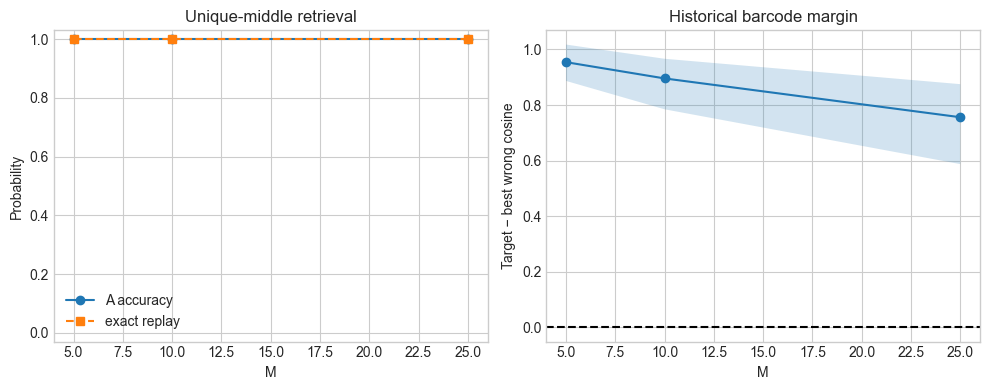

,accuracy,exact,margin_mean,margin_median,margin_q05,margin_q95,fraction_positive
M,,,,,,,
5,1.0,1.0,0.954136,0.963116,0.886716,1.017457,1.0
10,1.0,1.0,0.895637,0.901554,0.784625,0.966335,1.0
25,1.0,1.0,0.756092,0.777003,0.587491,0.875017,1.0


In [6]:
t3=[]
for seed in SEEDS:
 for bank in range(BANKS):
  for M in [5,10,25]:
   rng=np.random.default_rng(seed+700000+10000*bank+M);markers=rng.choice(NR,M,replace=False);pool=np.setdiff1d(np.arange(NR),markers);ep=[]
   for k in range(M):
    fill=rng.choice(pool,7,replace=False);ep.append(np.r_[fill[:3],markers[k],fill[3:]])
   ep=np.asarray(ep);mm=mem(ep);D,E,u,Br,Sr,pred=events(mm,ep[:,3:4]);base=rows(mm,D,E,u,Br,Sr,pred,np.arange(M),{'seed':seed,'bank':bank,'M':M})
   sims=(u@mm['V'].T)/(np.maximum(np.linalg.norm(u,axis=1,keepdims=True),EPS)*np.maximum(np.linalg.norm(mm['V'],axis=1),EPS)[None,:])
   for i,x in enumerate(base):x['historical_margin']=sims[i,i]-np.delete(sims[i],i).max();t3.append(x)
T3=pd.DataFrame(t3);T3.to_csv(ROOT/'test3_unique_middle.csv',index=False);T3[['seed','bank','M','target','historical_margin']].to_csv(ROOT/'test3_margin.csv',index=False)
g=T3.groupby('M');s=g.agg(accuracy=('A_top1','mean'),exact=('exact_replay','mean'),margin_mean=('historical_margin','mean'),margin_median=('historical_margin','median'),margin_q05=('historical_margin',lambda x:x.quantile(.05)),margin_q95=('historical_margin',lambda x:x.quantile(.95)),fraction_positive=('historical_margin',lambda x:np.mean(x>0)))
fig,ax=plt.subplots(1,2,figsize=(10,4));ax[0].plot(s.index,s.accuracy,'o-',label='A accuracy');ax[0].plot(s.index,s.exact,'s--',label='exact replay');ax[0].set(title='Unique-middle retrieval',xlabel='M',ylabel='Probability',ylim=(-.03,1.03));ax[0].legend();ax[1].plot(s.index,s.margin_mean,'o-',label='mean');ax[1].fill_between(s.index,s.margin_q05,s.margin_q95,alpha=.2);ax[1].axhline(0,color='k',ls='--');ax[1].set(title='Historical barcode margin',xlabel='M',ylabel='Target − best wrong cosine');fig.tight_layout();save(fig,'figure3_test3_margin.png');display(s)

## 4. Historical Test 4 — ambiguous pair and added evidence

For every $M$, each of 3 seeds has 4 banks and 5 tested pairs. Pair A/B shares `[x,y,z]` at positions 3–5; position 6 differs. The ambiguous cue is evaluated once per pair and the observed hard-WTA winner is classified as A, B, or irrelevant. Each pair is then queried twice with added discriminative evidence. No probability vector or mixed barcode is constructed.

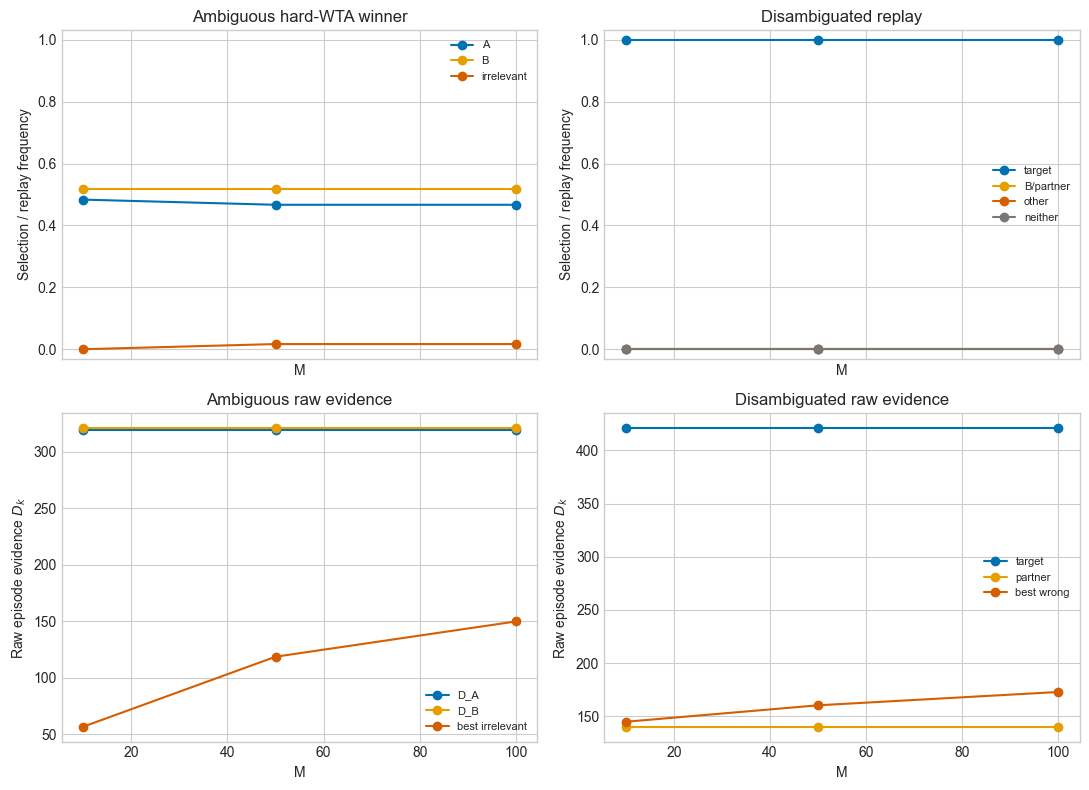

,seed,bank,pair,A,B,winner,D_A,D_B,D_best_irrelevant,D_AB_margin,winner_A,winner_B,winner_compatible,winner_irrelevant,replay_A,replay_B,replay_other,replay_neither
M,,,,,,,,,,,,,,,,,,
10,321002.0,1.5,2.0,4.0,5.0,4.516667,319.202078,320.771566,56.760968,36.60551,0.483333,0.516667,1.000000,0.000000,0.483333,0.516667,0.000000,0.0
50,321002.0,1.5,2.0,4.0,5.0,4.683333,319.202078,320.771566,118.672456,36.60551,0.466667,0.516667,0.983333,0.016667,0.466667,0.516667,0.016667,0.0
100,321002.0,1.5,2.0,4.0,5.0,4.683333,319.202078,320.771566,149.886525,36.60551,0.466667,0.516667,0.983333,0.016667,0.466667,0.516667,0.016667,0.0


,seed,bank,pair,target,partner,winner,D_target,D_partner,D_wrong_max,D_margin,winner_target,winner_partner,winner_other,replay_target,replay_partner,replay_other,replay_neither,exact_replay
M,,,,,,,,,,,,,,,,,,
10,321002.0,1.5,2.0,4.5,4.5,4.5,420.73154,140.197718,144.806801,275.924739,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
50,321002.0,1.5,2.0,4.5,4.5,4.5,420.73154,140.197718,160.297872,260.433668,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
100,321002.0,1.5,2.0,4.5,4.5,4.5,420.73154,140.197718,172.820560,247.910980,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [7]:
a4=[];d4=[]
for seed in SEEDS:
 for M in TEST4_M:
  for bank in range(BANKS):
   ep=orderbank(np.random.default_rng(seed+800000+10000*bank),M,L);pr=np.random.default_rng(seed+900000+10000*bank);pairs=[]
   for pi in range(5):
    a,b=2*pi,2*pi+1;shared=pr.choice(NR,3,replace=False);rem=np.setdiff1d(np.arange(NR),shared);disc=pr.choice(rem,2,replace=False);ep[a,2:5]=shared;ep[b,2:5]=shared;ep[a,5]=disc[0];ep[b,5]=disc[1];pairs.append((a,b))
   mm=mem(ep)
   for pi,(a,b) in enumerate(pairs):
    D,Dw,u,Br,Sr,pred=events(mm,ep[a:a+1,2:5]);winner=int(D[0].argmax());out=pred[0];exact=np.array([np.array_equal(out,x) for x in ep]);other=np.delete(np.arange(M),[a,b])
    a4.append({'seed':seed,'bank':bank,'M':M,'pair':pi,'A':a,'B':b,'winner':winner,'D_A':D[0,a],'D_B':D[0,b],'D_best_irrelevant':D[0,other].max(),'D_AB_margin':abs(D[0,a]-D[0,b]),'winner_A':winner==a,'winner_B':winner==b,'winner_compatible':winner in [a,b],'winner_irrelevant':winner in other,'replay_A':exact[a],'replay_B':exact[b],'replay_other':exact[other].any(),'replay_neither':not exact.any(),'D_vector':json.dumps(D[0].tolist()),'D_wta_vector':json.dumps(Dw[0].tolist())})
    for target,partner in [(a,b),(b,a)]:
     D,Dw,u,Br,Sr,pred=events(mm,ep[target:target+1,2:6]);winner=int(D[0].argmax());out=pred[0];exact=np.array([np.array_equal(out,x) for x in ep]);other=np.delete(np.arange(M),[a,b])
     d4.append({'seed':seed,'bank':bank,'M':M,'pair':pi,'target':target,'partner':partner,'winner':winner,'D_target':D[0,target],'D_partner':D[0,partner],'D_wrong_max':np.delete(D[0],target).max(),'D_margin':D[0,target]-np.delete(D[0],target).max(),'winner_target':winner==target,'winner_partner':winner==partner,'winner_other':winner in other,'replay_target':exact[target],'replay_partner':exact[partner],'replay_other':exact[other].any(),'replay_neither':not exact.any(),'exact_replay':exact[target],'D_vector':json.dumps(D[0].tolist()),'D_wta_vector':json.dumps(Dw[0].tolist())})
A4=pd.DataFrame(a4);D4=pd.DataFrame(d4);A4.to_csv(ROOT/'test4_ambiguous.csv',index=False);D4.to_csv(ROOT/'test4_disambiguated.csv',index=False)
fig,ax=plt.subplots(2,2,figsize=(11,8),sharex=True)
for m,lab,col in [('winner_A','A','#0072B2'),('winner_B','B','#E69F00'),('winner_irrelevant','irrelevant','#D55E00')]:z=A4.groupby('M')[m].mean();ax[0,0].plot(z.index,z,'o-',label=lab,color=col)
for m,lab,col in [('D_A','D_A','#0072B2'),('D_B','D_B','#E69F00'),('D_best_irrelevant','best irrelevant','#D55E00')]:z=A4.groupby('M')[m].mean();ax[1,0].plot(z.index,z,'o-',label=lab,color=col)
for m,lab,col in [('replay_target','target','#0072B2'),('replay_partner','B/partner','#E69F00'),('replay_other','other','#D55E00'),('replay_neither','neither','#777777')]:z=D4.groupby('M')[m].mean();ax[0,1].plot(z.index,z,'o-',label=lab,color=col)
for m,lab,col in [('D_target','target','#0072B2'),('D_partner','partner','#E69F00'),('D_wrong_max','best wrong','#D55E00')]:z=D4.groupby('M')[m].mean();ax[1,1].plot(z.index,z,'o-',label=lab,color=col)
for a,t in zip(ax[0],['Ambiguous hard-WTA winner','Disambiguated replay']):a.set(title=t,xlabel='M',ylabel='Selection / replay frequency',ylim=(-.03,1.03));a.legend(fontsize=8)
for a,t in zip(ax[1],['Ambiguous raw evidence','Disambiguated raw evidence']):a.set(title=t,xlabel='M',ylabel=r'Raw episode evidence $D_k$');a.legend(fontsize=8)
fig.tight_layout();save(fig,'figure4_test4_ambiguity.png');display(A4.groupby('M').mean(numeric_only=True));display(D4.groupby('M').mean(numeric_only=True))

## 5. Historical Test 5 — nested distributed cue-feature masking

Only the original masking test is reproduced. For each unique middle four-event cue `episode[2:6]`, one feature permutation per event is frozen. Increasing $q$ removes a nested prefix of that same permutation from $W^{CR}_{:,r_t}$; there is no amplitude compensation and no event deletion.

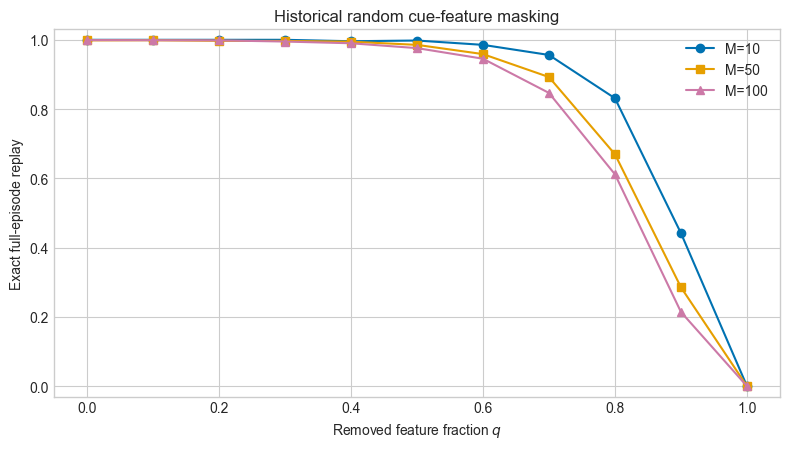

A_top1    D_margin  barcode_similarity  S0_similarity  \
M   feature_loss                                                            
10  0.0           1.000000  321.583546            1.000000       1.000000   
    0.1           1.000000  262.922839            1.000000       1.000000   
    0.2           1.000000  211.470654            1.000000       1.000000   
    0.3           1.000000  162.372754            1.000000       1.000000   
    0.4           0.995833  118.054338            0.995792       0.995757   
    0.5           0.997917   80.566169            0.997891       0.997866   
    0.6           0.985417   48.976371            0.985584       0.985243   
    0.7           0.956250   23.129489            0.955792       0.955710   
    0.8           0.831250    7.107988            0.831056       0.831744   
    0.9           0.454167    0.631428            0.442624       0.442063   
    1.0           0.100000    0.000000            0.000000       0.000000   
50  0.0           0.998333  286.691724            0.998425       0.998423   
    0.1           0.998750  234.706153            0.998819       0.998817   
    0.2           0.997083  186.196329            0.997199       0.997213   
    0.3           0.996667  141.745115            0.996795       0.996770   
    0.4           0.994583  102.442376            0.994632       0.994621   
    0.5           0.985417   68.618399            0.985796       0.985712   
    0.6           0.958750   40.314586            0.959282       0.958982   
    0.7           0.892500   18.887798            0.893599       0.893456   
    0.8           0.669583    4.732900            0.670893       0.670461   
    0.9           0.286667   -0.208554            0.286877       0.286615   
    1.0           0.020000    0.000000            0.000000       0.000000   
100 0.0           0.999167  263.163559            0.999115       0.999114   
    0.1           0.998750  214.724776            0.998829       0.998818   
    0.2           0.998333  169.773125            0.998363       0.998356   
    0.3           0.995000  128.625756            0.994982       0.994949   
    0.4           0.990000   92.995991            0.990022       0.989951   
    0.5           0.976042   61.804106            0.976307       0.976220   
    0.6           0.945417   35.398077            0.946236       0.945973   
    0.7           0.846667   15.770236            0.848344       0.848213   
    0.8           0.611667    3.371355            0.613597       0.613650   
    0.9           0.214375   -0.580657            0.217818       0.217089   
    1.0           0.010000    0.000000            0.000000       0.000000   

                  exact_replay  
M   feature_loss                
10  0.0               1.000000  
    0.1               1.000000  
    0.2               1.000000  
    0.3               1.000000  
    0.4               0.995833  
    0.5               0.997917  
    0.6               0.985417  
    0.7               0.956250  
    0.8               0.831250  
    0.9               0.441667  
    1.0               0.000000  
50  0.0               0.998333  
    0.1               0.998750  
    0.2               0.997083  
    0.3               0.996667  
    0.4               0.994583  
    0.5               0.985417  
    0.6               0.958750  
    0.7               0.892500  
    0.8               0.669583  
    0.9               0.285417  
    1.0               0.000000  
100 0.0               0.999167  
    0.1               0.998750  
    0.2               0.998333  
    0.3               0.995000  
    0.4               0.990000  
    0.5               0.976042  
    0.6               0.945417  
    0.7               0.846667  
    0.8               0.611667  
    0.9               0.214167  
    1.0               0.000000

In [8]:
def maskedC(cue,ranks,q):
 c=np.zeros((1,NC));n=int(round(q*NC));keep=ranks>=n
 for t,event in enumerate(cue):c=np.tanh(G*(c@r.W_CC.T)+r.W_CR[:,event][None,:]*keep[:,t])
 return c
def maskedC_grid(cue,ranks,qgrid):
 n=np.array([int(round(float(q)*NC)) for q in qgrid])
 keep=ranks[0][None,:,:]>=n[:,None,None]
 c=np.zeros((len(qgrid),NC))
 for t,event in enumerate(cue):c=np.tanh(G*(c@r.W_CC.T)+r.W_CR[:,event][None,:]*keep[:,t,:])
 return c
_probe_ranks=np.arange(NC).reshape(1,1,NC).repeat(4,axis=1)
_probe_cue=np.arange(4)
assert np.allclose(maskedC_grid(_probe_cue,_probe_ranks,QGRID),
                   np.vstack([maskedC(_probe_cue,_probe_ranks,q) for q in QGRID]))
def contiguous(cue,ep):return {i for i,x in enumerate(ep) if any(np.array_equal(cue,x[s:s+len(cue)]) for s in range(len(x)-len(cue)+1))}
t5=[]
for seed in SEEDS:
 for bank in range(BANKS):
  for M in [10,50,100]:
   mm=cache[(seed,bank,M)];ep=mm['ep']
   for target,cue in enumerate(ep[:,2:6]):
    if contiguous(cue,ep)!={target}:continue
    for rep in range(MASK_REPS):
     rg=np.random.default_rng(np.random.SeedSequence([seed,bank,M,target,rep,5005]));ranks=np.empty((1,4,NC),int)
     for t in range(4):perm=rg.permutation(NC);ranks[0,t,perm]=np.arange(NC)
     Cqueries=maskedC_grid(cue,ranks,QGRID)
     D,E,u,Br,Sr,pred=fromq(mm,Cqueries)
     for qi,q in enumerate(QGRID):
      rec=rows(mm,D[qi:qi+1],E[qi:qi+1],u[qi:qi+1],Br[qi:qi+1],Sr[qi:qi+1],pred[qi:qi+1],[target],{'seed':seed,'bank':bank,'M':M,'mask_replicate':rep,'feature_loss':q})[0];t5.append(rec)
T5=pd.DataFrame(t5);T5.to_csv(ROOT/'test5_feature_masking.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4.6));
for M,col,mark in zip([10,50,100],['#0072B2','#E69F00','#CC79A7'],['o','s','^']):z=T5[T5.M==M].groupby('feature_loss').exact_replay.mean();ax.plot(z.index,z,'-'+mark,color=col,label=f'M={M}')
ax.set(title='Historical random cue-feature masking',xlabel=r'Removed feature fraction $q$',ylabel='Exact full-episode replay',ylim=(-.03,1.03));ax.legend();fig.tight_layout();save(fig,'figure5_test5_masking.png');display(T5.groupby(['M','feature_loss']).mean(numeric_only=True)[['A_top1','D_margin','barcode_similarity','S0_similarity','exact_replay']])

## 6. Historical comparison and conclusions

In [9]:
# Historical numbers below are quoted only from actual saved notebook Markdown/output.
hist=[
 ['Test 1','V1.0 indexed replay remained strong; positional C/B effect documented (quantitative values retained in source).'],
 ['Test 2','Actual historical summary: V1.0 prefix/middle m=3, M=5/10 mean 0.094; Idea2 0.994.'],
 ['Test 3','Actual historical Idea2 unique-middle addressing 1.000.'],
 ['Test 4','Actual historical Idea2 ambiguity F1 0.966; disambiguation 1.000.'],
 ['Test 5','Actual historical Idea2 addressing plateau q=0–0.6: 0.980–1.000; q=.7/.8/.9 = .936/.777/.344.']]
current=[f"90% overlap exact={OV.query('requested_overlap==.9').exact_replay.mean():.3f}; 7/8 positional exact={POS.exact_replay.mean():.3f}",
 f"m=3 M=5/10 prefix/middle/suffix exact={T2.query('M in [5,10] and cue_length==3').groupby('cue_type').exact_replay.mean().round(3).to_dict()}",
 f"accuracy by M={T3.groupby('M').A_top1.mean().round(3).to_dict()}; margin={T3.groupby('M').historical_margin.mean().round(3).to_dict()}",
 f"ambiguous compatible winner={A4.winner_compatible.mean():.3f}; disambiguated target replay={D4.replay_target.mean():.3f}",
 f"exact replay by q={T5.groupby('feature_loss').exact_replay.mean().round(3).to_dict()}"]
COMP=pd.DataFrame({'Test':[x[0] for x in hist],'Historical V1.0/Idea2 behavior':[x[1] for x in hist],'Canonical V1.2 behavior':current,'Main change':['Hard WTA removes barcode mixing after contextual evidence.','The maximum-evidence episode alone supplies B.','Unique diagnostic cues select one stored barcode.','Ambiguity is expressed as winner frequency across trials, not a mixed barcode.','The same nested-mask test measures winner stability under degradation.']});COMP.to_csv(ROOT/'historical_comparison.csv',index=False)
SUM=pd.DataFrame([{'test1_overlap90_exact':OV.query('requested_overlap==.9').exact_replay.mean(),'test1_positional_exact':POS.exact_replay.mean(),'test2_m3_lowload_exact':T2.query('M in [5,10] and cue_length==3').exact_replay.mean(),'test3_exact':T3.exact_replay.mean(),'test4_compatible_winner':A4.winner_compatible.mean(),'test4_disambiguated_exact':D4.replay_target.mean(),'test5_mean_exact':T5.exact_replay.mean()}]);SUM.to_csv(ROOT/'summary.csv',index=False);display(COMP);display(SUM)
summary=f"""# HIESM V1.2 canonical validation — deterministic hard-WTA A

1. At 90% requested overlap, exact replay is {OV.query("requested_overlap==.9").exact_replay.mean():.3f}; across the explicit 7/8 mismatch-position control it is {POS.exact_replay.mean():.3f}.
2. Final-C distance varies by mismatch position from {POS.groupby("different_position").C_cosine_distance.mean().min():.4f} to {POS.groupby("different_position").C_cosine_distance.mean().max():.4f}; the old recency geometry remains.
3. Positional geometry yields replay range {POS.groupby("different_position").exact_replay.mean().min():.3f}–{POS.groupby("different_position").exact_replay.mean().max():.3f}; this states whether geometry becomes functional failure.
4. Test-2 $m=3$, $M=5/10$ exact replay: {T2.query("M in [5,10] and cue_length==3").groupby("cue_type").exact_replay.mean().round(3).to_dict()}.
5. Compare these location curves with historical V1.0 prefix/middle mean 0.094; V1.2's hard-WTA Addressor determines whether severe location dependence disappeared.
6. Cue-length dependence is {T2.query("M in [5,10]").groupby(["cue_type","cue_length"]).exact_replay.mean().round(3).to_dict()}.
7. Test-3 accuracy by M: {T3.groupby("M").A_top1.mean().round(3).to_dict()}.
8. Historical barcode margin by M: {T3.groupby("M").historical_margin.mean().round(3).to_dict()}.
9. Ambiguous hard-WTA winner frequencies are A={A4.winner_A.mean():.3f}, B={A4.winner_B.mean():.3f}, and irrelevant={A4.winner_irrelevant.mean():.3f}.
10. Compatible-winner frequency by M is {A4.groupby("M").winner_compatible.mean().round(3).to_dict()}; ambiguity is measured across trials rather than represented by barcode averaging.
11. Ambiguous replay probabilities: A={A4.replay_A.mean():.3f}, B={A4.replay_B.mean():.3f}, other={A4.replay_other.mean():.3f}, neither={A4.replay_neither.mean():.3f}.
12. Added evidence restores target exact replay to {D4.replay_target.mean():.3f}.
13. Raw $D_A$, $D_B$, and best-irrelevant evidence remain visible even though only the largest-evidence episode supplies the retrieved barcode.
14. Masking exact replay by q is {T5.groupby("feature_loss").exact_replay.mean().round(3).to_dict()}.
15. No monotonic fit is imposed; the raw curve determines whether a plateau-then-decline remains.
16. Hard WTA converts episode addressing into a single stored-barcode selection and eliminates downstream barcode mixtures.
17. C's temporal recency geometry remains; any remaining replay loss reflects an incorrect evidence winner or downstream storage failure.
18. Unlike the generalized benchmark, this replication exposes mismatch-position sensitivity, location-specific cue-length curves, load-dependent historical barcode margin, and exact old nested-mask loads.
""";(ROOT/'summary.md').write_text(summary);display(Markdown(summary))

,Test,Historical V1.0/Idea2 behavior,Canonical V1.2 behavior,Main change
0,Test 1,V1.0 indexed replay remained strong; positiona...,90% overlap exact=1.000; 7/8 positional exact=...,Hard WTA removes barcode mixing after contextu...
1,Test 2,Actual historical summary: V1.0 prefix/middle ...,m=3 M=5/10 prefix/middle/suffix exact={'middle...,The maximum-evidence episode alone supplies B.
2,Test 3,Actual historical Idea2 unique-middle addressi...,"accuracy by M={5: 1.0, 10: 1.0, 25: 1.0}; marg...",Unique diagnostic cues select one stored barcode.
3,Test 4,Actual historical Idea2 ambiguity F1 0.966; di...,ambiguous compatible winner=0.989; disambiguat...,Ambiguity is expressed as winner frequency acr...
4,Test 5,Actual historical Idea2 addressing plateau q=0...,"exact replay by q={0.0: 0.999, 0.1: 0.999, 0.2...",The same nested-mask test measures winner stab...


,test1_overlap90_exact,test1_positional_exact,test2_m3_lowload_exact,test3_exact,test4_compatible_winner,test4_disambiguated_exact,test5_mean_exact
0,1.0,0.986146,0.996296,1.0,0.988889,1.0,0.788897


# HIESM V1.2 canonical validation — deterministic hard-WTA A

1. At 90% requested overlap, exact replay is 1.000; across the explicit 7/8 mismatch-position control it is 0.986.
2. Final-C distance varies by mismatch position from 0.0486 to 0.3173; the old recency geometry remains.
3. Positional geometry yields replay range 0.955–1.000; this states whether geometry becomes functional failure.
4. Test-2 $m=3$, $M=5/10$ exact replay: {'middle': 0.989, 'prefix': 1.0, 'suffix': 1.0}.
5. Compare these location curves with historical V1.0 prefix/middle mean 0.094; V1.2's hard-WTA Addressor determines whether severe location dependence disappeared.
6. Cue-length dependence is {('middle', 2): 0.961, ('middle', 3): 0.989, ('middle', 4): 1.0, ('prefix', 2): 1.0, ('prefix', 3): 1.0, ('prefix', 4): 1.0, ('suffix', 2): 0.944, ('suffix', 3): 1.0, ('suffix', 4): 1.0}.
7. Test-3 accuracy by M: {5: 1.0, 10: 1.0, 25: 1.0}.
8. Historical barcode margin by M: {5: 0.954, 10: 0.896, 25: 0.756}.
9. Ambiguous hard-WTA winner frequencies are A=0.472, B=0.517, and irrelevant=0.011.
10. Compatible-winner frequency by M is {10: 1.0, 50: 0.983, 100: 0.983}; ambiguity is measured across trials rather than represented by barcode averaging.
11. Ambiguous replay probabilities: A=0.472, B=0.517, other=0.011, neither=0.000.
12. Added evidence restores target exact replay to 1.000.
13. Raw $D_A$, $D_B$, and best-irrelevant evidence remain visible even though only the largest-evidence episode supplies the retrieved barcode.
14. Masking exact replay by q is {0.0: 0.999, 0.1: 0.999, 0.2: 0.998, 0.3: 0.996, 0.4: 0.992, 0.5: 0.98, 0.6: 0.952, 0.7: 0.868, 0.8: 0.643, 0.9: 0.251, 1.0: 0.0}.
15. No monotonic fit is imposed; the raw curve determines whether a plateau-then-decline remains.
16. Hard WTA converts episode addressing into a single stored-barcode selection and eliminates downstream barcode mixtures.
17. C's temporal recency geometry remains; any remaining replay loss reflects an incorrect evidence winner or downstream storage failure.
18. Unlike the generalized benchmark, this replication exposes mismatch-position sensitivity, location-specific cue-length curves, load-dependent historical barcode margin, and exact old nested-mask loads.


In [10]:
req=['test1_overlap.csv','test1_differing_position.csv','test1_suffix_overlap.csv','test2_partial_location.csv','test2_cue_length.csv','test3_unique_middle.csv','test3_margin.csv','test4_ambiguous.csv','test4_disambiguated.csv','test5_feature_masking.csv','historical_settings_recovered.csv','historical_comparison.csv','summary.csv','summary.md']
tables=[OV,POS,SUFFIX_OV,T2,T3,A4,D4,T5]
audit_mm=cache[(SEEDS[0],0,10)];audit_D,audit_Dw,audit_u,audit_Br,_,_=events(audit_mm,audit_mm['ep'])
audit_total=audit_Dw.sum(1,keepdims=True);audit_expected_Br=muB+np.divide(audit_Dw@audit_mm['V'],audit_total,out=np.zeros_like(audit_u),where=audit_total>0)
checks={'version':'HIESM V1.2','theta':TH==2.84,'hard_WTA':True,'no_soft_competition':True,'no_alpha':True,'test1_7of8':set(POS.different_position)==set(range(1,9)),'test1_suffix_grid':set(SUFFIX_OV.requested_overlap)==set(OVERLAPS),'test2_locations':set(T2.cue_type)==set(CUE_TYPES),'test3_M':set(T3.M)=={5,10,25},'test4_protocol':len(A4)==3*4*5*3 and len(D4)==3*4*5*2*3,'no_weight_columns':all(not any(c.startswith('w_') for c in x.columns) for x in tables),'A_to_B_association':np.allclose(audit_u,audit_Dw@audit_mm['V']) and np.allclose(audit_Br,audit_expected_Br),'one_WTA_winner':np.all(np.count_nonzero(audit_Dw,axis=1)==1),'test5_nested':T5.groupby(['seed','bank','M','target','mask_replicate']).feature_loss.nunique().eq(11).all(),'all_outputs':all((ROOT/x).exists() for x in req),'six_figures':len(list(FIG.glob('*.png')))==6}
print(checks);assert all(bool(v) for k,v in checks.items() if k!='version')

{'version': 'HIESM V1.2', 'theta': True, 'hard_WTA': True, 'no_soft_competition': True, 'no_alpha': True, 'test1_7of8': True, 'test1_suffix_grid': True, 'test2_locations': True, 'test3_M': True, 'test4_protocol': True, 'no_weight_columns': True, 'A_to_B_association': True, 'one_WTA_winner': np.True_, 'test5_nested': np.True_, 'all_outputs': True, 'six_figures': True}
